In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

data = {
    'Order_ID': [101, 102, 103, 104, 105, 106, 107, 108, 108, 109],
    'Product': ['Laptop', 'Mouse', 'Keyboard', 'Monitor',
                'Laptop', 'Mouse', 'Keyboard', 'Monitor',
                'Monitor', 'Laptop'],
    'Category': ['Electronics'] * 10,
    'Quantity': [2, 5, 3, 1, 2, 4, 3, 1, 1, 100],
    'Price': [50000, 500, 1500, 12000, 50000,
              500, 1500, 12000, 12000, 50000],
    'Customer_Age': [25, 30, np.nan, 35, 28,
                     40, 32, 29, 29, 45],
    'Order_Date': ['2026-01-05', '2026-01-10',
                   '2026-02-03', '2026-02-15',
                   '2026-03-01', '2026-03-10',
                   '2026-04-05', '2026-04-12',
                   '2026-04-12', '2026-05-01']
}

df = pd.DataFrame(data)

df


,Order_ID,Product,Category,Quantity,Price,Customer_Age,Order_Date
0,101,Laptop,Electronics,2,50000,25.0,2026-01-05
1,102,Mouse,Electronics,5,500,30.0,2026-01-10
2,103,Keyboard,Electronics,3,1500,NaN,2026-02-03
3,104,Monitor,Electronics,1,12000,35.0,2026-02-15
4,105,Laptop,Electronics,2,50000,28.0,2026-03-01
5,106,Mouse,Electronics,4,500,40.0,2026-03-10
6,107,Keyboard,Electronics,3,1500,32.0,2026-04-05
7,108,Monitor,Electronics,1,12000,29.0,2026-04-12
8,108,Monitor,Electronics,1,12000,29.0,2026-04-12
9,109,Laptop,Electronics,100,50000,45.0,2026-05-01


In [ ]:

df.to_csv("raw_sales_data.csv", index=False)

print("Raw dataset saved successfully!")


Raw dataset saved successfully!


In [ ]:
print(df.isnull().sum())


Order_ID        0
Product         0
Category        0
Quantity        0
Price           0
Customer_Age    1
Order_Date      0
dtype: int64


In [ ]:
df_cleaned = df.copy()


median_age = df_cleaned['Customer_Age'].median()

df_cleaned['Customer_Age'] = (
    df_cleaned['Customer_Age'].fillna(median_age)
)

print("Median Age:", median_age)

print("\nMissing Values After Cleaning:")
print(df_cleaned.isnull().sum())


Median Age: 30.0

Missing Values After Cleaning:
Order_ID        0
Product         0
Category        0
Quantity        0
Price           0
Customer_Age    0
Order_Date      0
dtype: int64


In [ ]:

df_cleaned


,Order_ID,Product,Category,Quantity,Price,Customer_Age,Order_Date
0,101,Laptop,Electronics,2,50000,25.0,2026-01-05
1,102,Mouse,Electronics,5,500,30.0,2026-01-10
2,103,Keyboard,Electronics,3,1500,30.0,2026-02-03
3,104,Monitor,Electronics,1,12000,35.0,2026-02-15
4,105,Laptop,Electronics,2,50000,28.0,2026-03-01
5,106,Mouse,Electronics,4,500,40.0,2026-03-10
6,107,Keyboard,Electronics,3,1500,32.0,2026-04-05
7,108,Monitor,Electronics,1,12000,29.0,2026-04-12
8,108,Monitor,Electronics,1,12000,29.0,2026-04-12
9,109,Laptop,Electronics,100,50000,45.0,2026-05-01


In [ ]:
print("Total Duplicate Rows:", df_cleaned.duplicated().sum())

df_cleaned[df_cleaned.duplicated(keep=False)]


Total Duplicate Rows: 1


,Order_ID,Product,Category,Quantity,Price,Customer_Age,Order_Date
7,108,Monitor,Electronics,1,12000,29.0,2026-04-12
8,108,Monitor,Electronics,1,12000,29.0,2026-04-12


In [ ]:
df_cleaned = df_cleaned.drop_duplicates()


df_cleaned = df_cleaned.reset_index(drop=True)

print("Duplicate records removed successfully!")

print("Total Rows After Cleaning:", len(df_cleaned))


Duplicate records removed successfully!
Total Rows After Cleaning: 9


In [ ]:

print("Remaining Duplicates:", df_cleaned.duplicated().sum())

df_cleaned


Remaining Duplicates: 0


,Order_ID,Product,Category,Quantity,Price,Customer_Age,Order_Date
0,101,Laptop,Electronics,2,50000,25.0,2026-01-05
1,102,Mouse,Electronics,5,500,30.0,2026-01-10
2,103,Keyboard,Electronics,3,1500,30.0,2026-02-03
3,104,Monitor,Electronics,1,12000,35.0,2026-02-15
4,105,Laptop,Electronics,2,50000,28.0,2026-03-01
5,106,Mouse,Electronics,4,500,40.0,2026-03-10
6,107,Keyboard,Electronics,3,1500,32.0,2026-04-05
7,108,Monitor,Electronics,1,12000,29.0,2026-04-12
8,109,Laptop,Electronics,100,50000,45.0,2026-05-01


In [ ]:
print(df_cleaned.dtypes)


Order_ID          int64
Product          object
Category         object
Quantity          int64
Price             int64
Customer_Age    float64
Order_Date       object
dtype: object


In [ ]:
df_cleaned['Order_Date'] = pd.to_datetime(
    df_cleaned['Order_Date'],
    errors='coerce'
)

print(df_cleaned.dtypes)


Order_ID                 int64
Product                 object
Category                object
Quantity                 int64
Price                    int64
Customer_Age           float64
Order_Date      datetime64[ns]
dtype: object


In [ ]:
print("Invalid Quantities:",
      (df_cleaned['Quantity'] <= 0).sum())

print("Invalid Prices:",
      (df_cleaned['Price'] < 0).sum())

print("Invalid Customer Ages:",
      ((df_cleaned['Customer_Age'] < 0) |
       (df_cleaned['Customer_Age'] > 120)).sum())

print("Invalid Dates:",
      df_cleaned['Order_Date'].isna().sum())

print("Duplicate Order IDs:",
      df_cleaned['Order_ID'].duplicated().sum())


Invalid Quantities: 0
Invalid Prices: 0
Invalid Customer Ages: 0
Invalid Dates: 0
Duplicate Order IDs: 0


In [ ]:
df_cleaned['Revenue'] = (
    df_cleaned['Quantity'] * df_cleaned['Price']
)


df_cleaned


,Order_ID,Product,Category,Quantity,Price,Customer_Age,Order_Date,Revenue
0,101,Laptop,Electronics,2,50000,25.0,2026-01-05,100000
1,102,Mouse,Electronics,5,500,30.0,2026-01-10,2500
2,103,Keyboard,Electronics,3,1500,30.0,2026-02-03,4500
3,104,Monitor,Electronics,1,12000,35.0,2026-02-15,12000
4,105,Laptop,Electronics,2,50000,28.0,2026-03-01,100000
5,106,Mouse,Electronics,4,500,40.0,2026-03-10,2000
6,107,Keyboard,Electronics,3,1500,32.0,2026-04-05,4500
7,108,Monitor,Electronics,1,12000,29.0,2026-04-12,12000
8,109,Laptop,Electronics,100,50000,45.0,2026-05-01,5000000


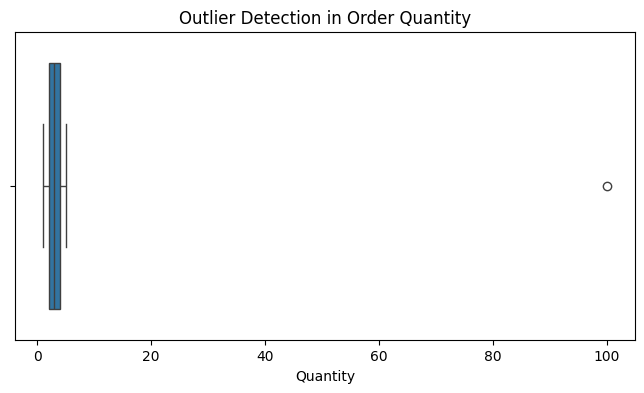

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df_cleaned['Quantity'])

plt.title("Outlier Detection in Order Quantity")
plt.xlabel("Quantity")
plt.show()


In [ ]:

Q1 = df_cleaned['Quantity'].quantile(0.25)
Q3 = df_cleaned['Quantity'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_cleaned[
    (df_cleaned['Quantity'] < lower_bound) |
    (df_cleaned['Quantity'] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

outliers


Lower Bound: -1.0
Upper Bound: 7.0
Number of Outliers: 1


,Order_ID,Product,Category,Quantity,Price,Customer_Age,Order_Date,Revenue
8,109,Laptop,Electronics,100,50000,45.0,2026-05-01,5000000


In [ ]:
df_cleaned = df_cleaned[
    (df_cleaned['Quantity'] >= lower_bound) &
    (df_cleaned['Quantity'] <= upper_bound)
].copy()


df_cleaned.reset_index(drop=True, inplace=True)

print("Rows After Outlier Removal:", len(df_cleaned))


Rows After Outlier Removal: 8


In [ ]:

print("Remaining Orders:", len(df_cleaned))
print("Maximum Quantity:", df_cleaned['Quantity'].max())

df_cleaned


Remaining Orders: 8
Maximum Quantity: 5


,Order_ID,Product,Category,Quantity,Price,Customer_Age,Order_Date,Revenue
0,101,Laptop,Electronics,2,50000,25.0,2026-01-05,100000
1,102,Mouse,Electronics,5,500,30.0,2026-01-10,2500
2,103,Keyboard,Electronics,3,1500,30.0,2026-02-03,4500
3,104,Monitor,Electronics,1,12000,35.0,2026-02-15,12000
4,105,Laptop,Electronics,2,50000,28.0,2026-03-01,100000
5,106,Mouse,Electronics,4,500,40.0,2026-03-10,2000
6,107,Keyboard,Electronics,3,1500,32.0,2026-04-05,4500
7,108,Monitor,Electronics,1,12000,29.0,2026-04-12,12000


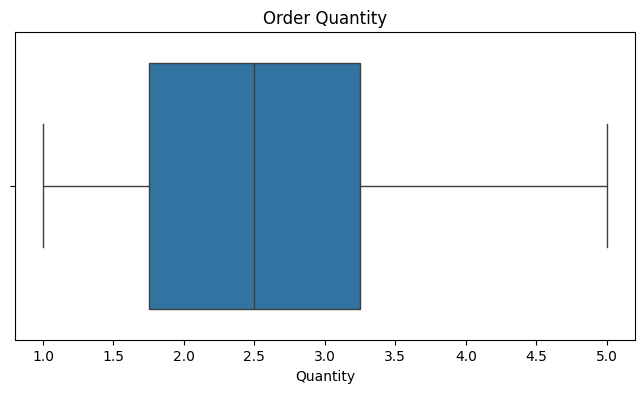

In [ ]:

plt.figure(figsize=(8, 4))

sns.boxplot(x=df_cleaned['Quantity'])

plt.title("Order Quantity")
plt.xlabel("Quantity")

plt.show()


In [ ]:
df_cleaned.to_csv("cleaned_sales_data.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [ ]:
print("Descriptive Statistics:")

df_cleaned.describe()


Descriptive Statistics:


,Order_ID,Quantity,Price,Customer_Age,Order_Date,Revenue
count,8.00000,8.000000,8.000000,8.000000,8,8.00000
mean,104.50000,2.625000,16000.000000,31.125000,2026-02-21 15:00:00,29687.50000
min,101.00000,1.000000,500.000000,25.000000,2026-01-05 00:00:00,2000.00000
25%,102.75000,1.750000,1250.000000,28.750000,2026-01-28 00:00:00,4000.00000
50%,104.50000,2.500000,6750.000000,30.000000,2026-02-22 00:00:00,8250.00000
75%,106.25000,3.250000,21500.000000,32.750000,2026-03-16 12:00:00,34000.00000
max,108.00000,5.000000,50000.000000,40.000000,2026-04-12 00:00:00,100000.00000
std,2.44949,1.407886,21530.708966,4.611709,NaN,43569.26956


In [ ]:
total_orders = df_cleaned['Order_ID'].nunique()

total_revenue = df_cleaned['Revenue'].sum()

average_revenue = df_cleaned['Revenue'].mean()

total_quantity = df_cleaned['Quantity'].sum()

average_quantity = df_cleaned['Quantity'].mean()

print("Total Orders:", total_orders)
print("Total Revenue: ₹", total_revenue)
print("Average Order Revenue: ₹", average_revenue)
print("Total Quantity Sold:", total_quantity)
print("Average Quantity Sold:", average_quantity)


Total Orders: 8
Total Revenue: ₹ 237500
Average Order Revenue: ₹ 29687.5
Total Quantity Sold: 21
Average Quantity Sold: 2.625


In [ ]:

print("Highest Product Price: ₹",
      df_cleaned['Price'].max())

print("Lowest Product Price: ₹",
      df_cleaned['Price'].min())

print("Median Product Price: ₹",
      df_cleaned['Price'].median())

print("Standard Deviation of Revenue:",
      df_cleaned['Revenue'].std())


Highest Product Price: ₹ 50000
Lowest Product Price: ₹ 500
Median Product Price: ₹ 6750.0
Standard Deviation of Revenue: 43569.26956009246


In [ ]:
numeric_data = df_cleaned[
    ['Quantity', 'Price', 'Customer_Age', 'Revenue']
]

correlation_matrix = numeric_data.corr()

print("Correlation Matrix:")
print(correlation_matrix)


Correlation Matrix:
              Quantity     Price  Customer_Age   Revenue
Quantity      1.000000 -0.464208      0.272281 -0.353850
Price        -0.464208  1.000000     -0.630167  0.990438
Customer_Age  0.272281 -0.630167      1.000000 -0.632909
Revenue      -0.353850  0.990438     -0.632909  1.000000


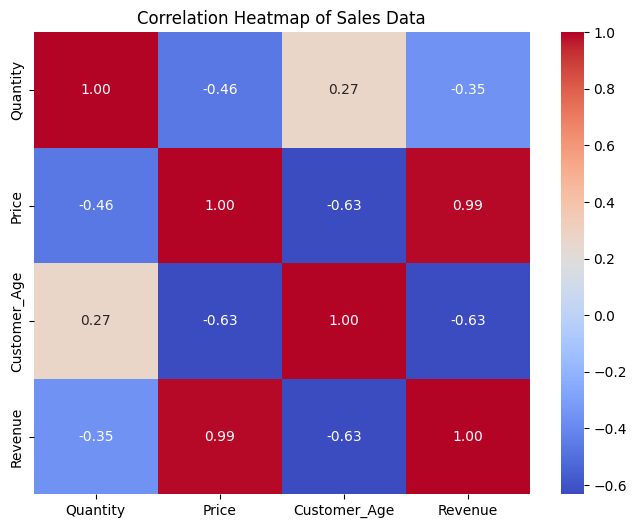

In [ ]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Sales Data")

plt.show()


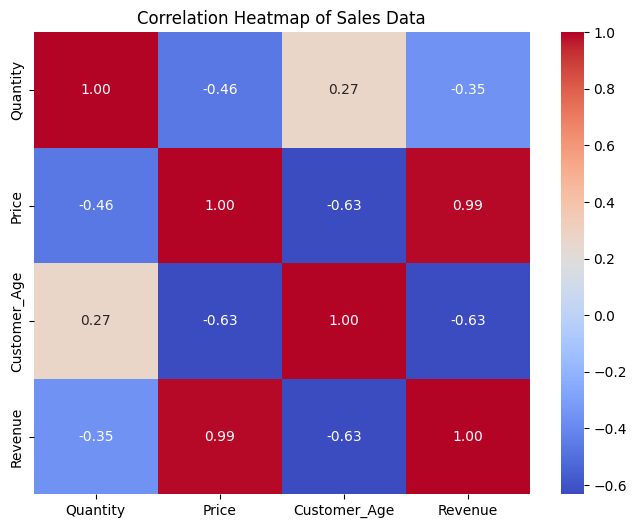

Correlation heatmap saved!


In [ ]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Sales Data")

plt.savefig(
    "correlation_heatmap.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Correlation heatmap saved!")


In [ ]:
df_cleaned['Month'] = (
    df_cleaned['Order_Date'].dt.to_period('M')
)

monthly_revenue = (
    df_cleaned.groupby('Month')['Revenue'].sum()
)

print("Monthly Revenue:")
print(monthly_revenue)


Monthly Revenue:
Month
2026-01    102500
2026-02     16500
2026-03    102000
2026-04     16500
Freq: M, Name: Revenue, dtype: int64


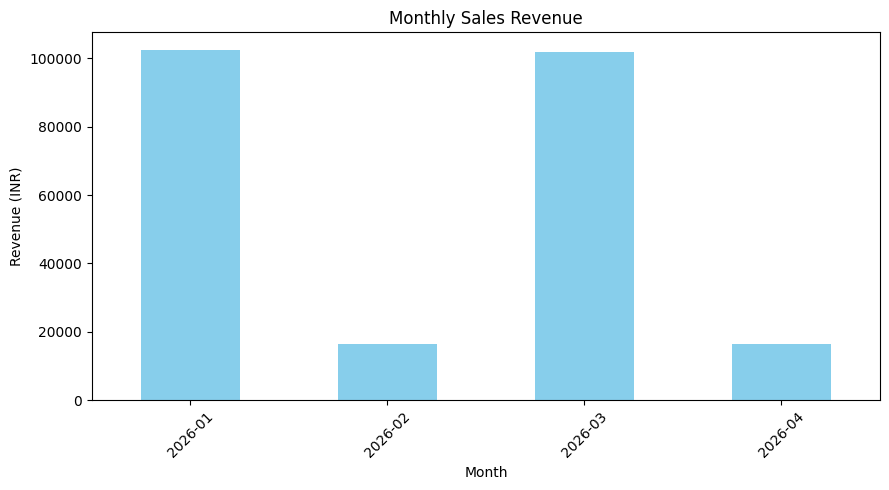

In [ ]:

plt.figure(figsize=(9, 5))

monthly_revenue.plot(kind='bar', color='skyblue')

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [ ]:
product_revenue = (
    df_cleaned.groupby('Product')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

print("Product-wise Revenue:")
print(product_revenue)


Product-wise Revenue:
Product
Laptop      200000
Monitor      24000
Keyboard      9000
Mouse         4500
Name: Revenue, dtype: int64


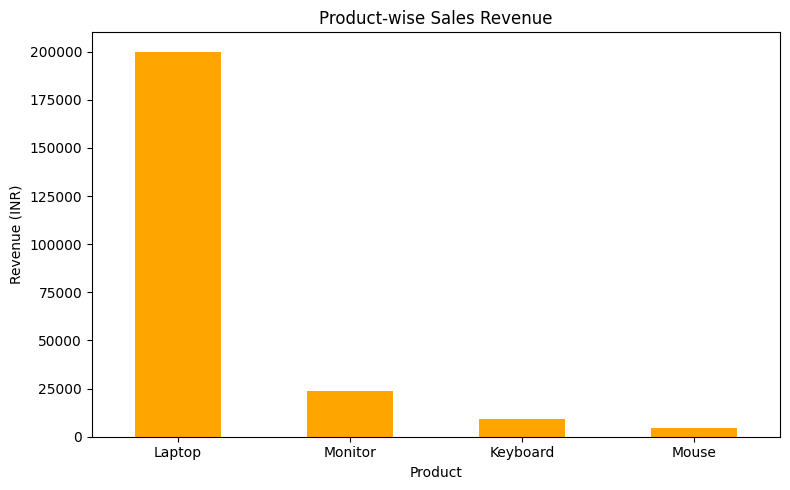

In [ ]:

plt.figure(figsize=(8, 5))

product_revenue.plot(kind='bar', color='orange')

plt.title("Product-wise Sales Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


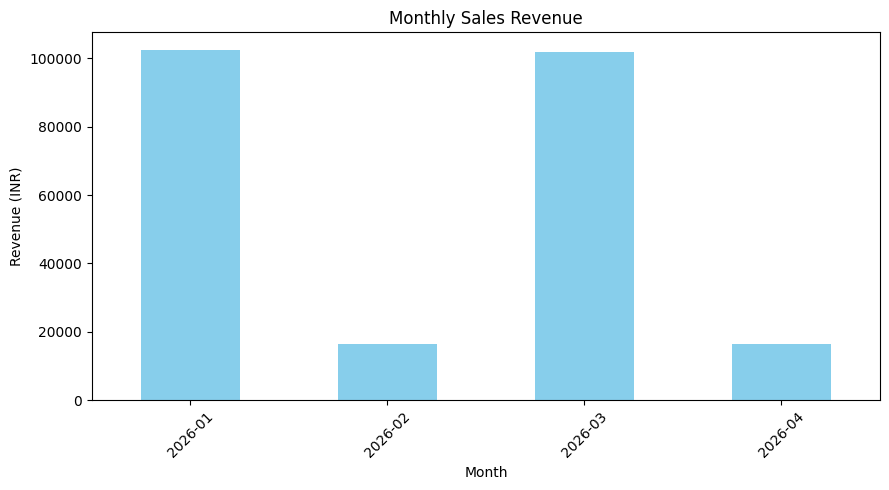

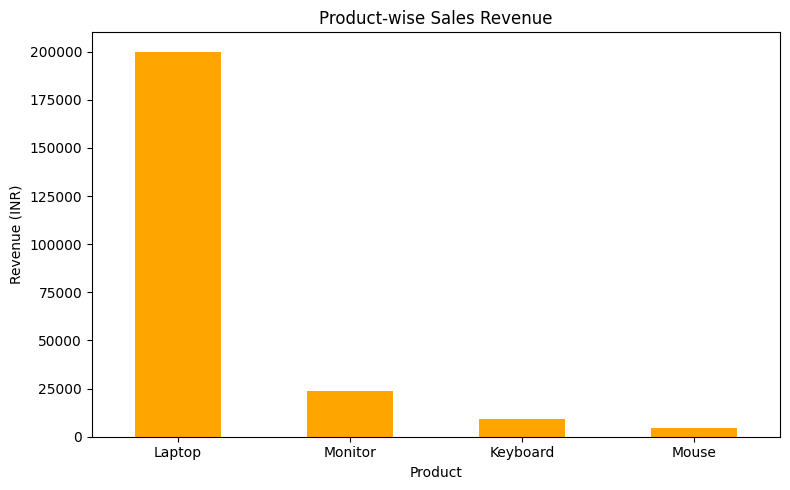

Both charts saved successfully!


In [ ]:

plt.figure(figsize=(9, 5))
monthly_revenue.plot(kind='bar', color='skyblue')
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("monthly_revenue.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
product_revenue.plot(kind='bar', color='orange')
plt.title("Product-wise Sales Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("product_revenue.png", dpi=300)
plt.show()

print("Both charts saved successfully!")
